<a href="https://colab.research.google.com/github/gngrexe/Floodsim_ubon/blob/main/flood_ubon_full_app.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# แอปพยากรณ์น้ำท่วม อุบลราชธานี (SWE + Random Forest + ข้อมูลจริงแบบเรียลไทม์)
รันเซลล์ 1 → 8 ตามลำดับ

ข้อมูลที่ใช้: ฝนพยากรณ์ (Open-Meteo), ปริมาณน้ำท่า GloFAS (Open-Meteo Flood API), ระดับความสูง SRTM และภาพ Sentinel-1 (Earth Engine) สำหรับเทียบน้ำท่วมจริงปี 2019

In [1]:
# เซลล์ 1: ติดตั้ง
!pip -q install earthengine-api streamlit folium scikit-learn joblib matplotlib numpy pandas requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 66.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 96.5 MB/s eta 0:00:00


In [2]:
# เซลล์ 2: เชื่อมต่อ Earth Engine
import ee
PROJECT = "floodsim-ubon"
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)
print("เชื่อมต่อ Google Earth Engine สำเร็จ")

เชื่อมต่อ Google Earth Engine สำเร็จ


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


ใช้ข้อมูล SRTM จริง
ขนาดกริด: (57, 65) | สูง: 110.6 - 142.1 ม.


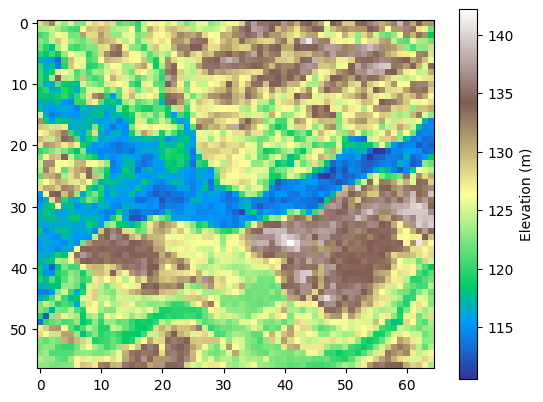

In [3]:
# เซลล์ 3: ดึง DEM (SRTM) พื้นที่อุบลฯ ที่ 500 ม.
import numpy as np
import matplotlib.pyplot as plt

DX = 500.0
region = ee.Geometry.Rectangle([104.70, 15.10, 105.00, 15.35])
try:
    dem = (ee.Image("USGS/SRTMGL1_003").select("elevation")
           .reduceResolution(ee.Reducer.mean(), maxPixels=1024)
           .reproject(crs="EPSG:32648", scale=DX))
    arr = dem.sampleRectangle(region=region, defaultValue=0).get("elevation").getInfo()
    Z = np.array(arr, dtype=float)
    print("ใช้ข้อมูล SRTM จริง")
except Exception as e:
    print("ดึง DEM ไม่สำเร็จ ใช้ DEM จำลองแทน:", e)
    y, x = np.mgrid[0:56, 0:65]
    Z = 120 + 0.15*x + 6*np.sin(x/9) + 0.05*y - 14*np.exp(-((y-28)/5.0)**2)
print("ขนาดกริด:", Z.shape, "| สูง:", round(Z.min(),1), "-", round(Z.max(),1), "ม.")
np.save("dem.npy", Z)
plt.imshow(Z, cmap="terrain"); plt.colorbar(label="Elevation (m)"); plt.show()

In [4]:
%%writefile swe.py
# เซลล์ 4: ไลบรารีกลาง (แบบจำลอง SWE + ดึงข้อมูลจริง) ใช้ร่วมกันทั้ง notebook และแอป
import numpy as np, pandas as pd, requests

G = 9.81
DX = 500.0
LAT, LON = 15.24, 104.85                      # ตัวเมืองอุบลฯ / แม่น้ำมูล
BOUNDS = [[15.10, 104.70], [15.35, 105.00]]   # [[ใต้, ตะวันตก], [เหนือ, ตะวันออก]]

# ---------------- แบบจำลอง SWE (local-inertial + CFL) ----------------
def simulate(Z, rain_mm, river_rise, dx=DX, hours=24, n=0.05, runoff=0.6):
    ny, nx = Z.shape
    level = np.percentile(Z, 2) + river_rise
    h = np.maximum(level - Z, 0.0)
    qx = np.zeros((ny, nx-1)); qy = np.zeros((ny-1, nx))
    rain_rate = runoff * rain_mm / 1000.0 / (hours*3600)
    T = hours*3600.0; t = 0.0
    hmax = h.copy()
    while t < T:
        dt = min(60.0, 0.7*dx/np.sqrt(G*max(h.max(), 0.1)), T - t)
        eta = Z + h
        hf = np.maximum(np.maximum(eta[:,1:], eta[:,:-1]) - np.maximum(Z[:,1:], Z[:,:-1]), 0)
        S = (eta[:,1:] - eta[:,:-1]) / dx
        qx = (qx - G*hf*dt*S) / (1 + G*dt*n**2*np.abs(qx)/np.maximum(hf, 1e-3)**(7/3))
        qx[hf <= 1e-3] = 0
        hf = np.maximum(np.maximum(eta[1:,:], eta[:-1,:]) - np.maximum(Z[1:,:], Z[:-1,:]), 0)
        S = (eta[1:,:] - eta[:-1,:]) / dx
        qy = (qy - G*hf*dt*S) / (1 + G*dt*n**2*np.abs(qy)/np.maximum(hf, 1e-3)**(7/3))
        qy[hf <= 1e-3] = 0
        d = np.zeros_like(h)
        d[:, :-1] -= qx; d[:, 1:] += qx
        d[:-1, :] -= qy; d[1:, :] += qy
        h = np.maximum(h + dt*d/dx + dt*rain_rate, 0)
        if not np.isfinite(h).all():
            raise ValueError("แบบจำลองไม่เสถียร (NaN) ตรวจสอบ CFL")
        hmax = np.maximum(hmax, h)
        t += dt
    return hmax

def make_features(Z, rain, rise):
    gy, gx = np.gradient(Z, DX)
    N = Z.size
    return np.column_stack([Z.ravel(), np.hypot(gx, gy).ravel(),
                            (Z - np.percentile(Z, 2)).ravel(),
                            np.full(N, rain), np.full(N, rise)])

# ---------------- ข้อมูลจริง (Open-Meteo ไม่ต้องใช้ key) ----------------
def _get(url, params):
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    return r.json()

def _series(j, key):
    return pd.Series(j["daily"][key], index=pd.to_datetime(j["daily"]["time"]), dtype=float)

def rain_recent(past=7, ahead=7):
    """ฝนรายวัน (มม.) ย้อนหลัง+พยากรณ์"""
    j = _get("https://api.open-meteo.com/v1/forecast", dict(
        latitude=LAT, longitude=LON, daily="precipitation_sum",
        past_days=past, forecast_days=ahead+1, timezone="Asia/Bangkok"))
    return _series(j, "precipitation_sum").fillna(0)

def rain_archive(start, end):
    j = _get("https://archive-api.open-meteo.com/v1/archive", dict(
        latitude=LAT, longitude=LON, daily="precipitation_sum",
        start_date=str(start), end_date=str(end), timezone="Asia/Bangkok"))
    return _series(j, "precipitation_sum").fillna(0)

def discharge_recent(past=7, ahead=7):
    """ปริมาณน้ำท่า GloFAS (ลบ.ม./วินาที) ที่แม่น้ำสายหลักใกล้อุบลฯ"""
    j = _get("https://flood-api.open-meteo.com/v1/flood", dict(
        latitude=LAT, longitude=LON, daily="river_discharge",
        past_days=past, forecast_days=ahead+1))
    return _series(j, "river_discharge")

def discharge_range(start, end):
    j = _get("https://flood-api.open-meteo.com/v1/flood", dict(
        latitude=LAT, longitude=LON, daily="river_discharge",
        start_date=str(start), end_date=str(end)))
    return _series(j, "river_discharge")

def eff_rain(s):
    """ฝนที่มีผล = ฝนวันนั้น + 0.5 x ฝนวันก่อน (ความชื้นดินสะสม)"""
    return (s + 0.5*s.shift(1).fillna(0)).clip(upper=450)

class Rating:
    """แปลงปริมาณน้ำท่า Q -> ระดับน้ำสูงกว่าปกติ (ม.) โดยให้ Q สูงสุดปี 2019 = rise_peak"""
    def __init__(self, q_hist, q_peak, rise_peak=8.0):
        self.q_low = float(np.nanpercentile(q_hist, 10))
        self.q_peak = float(q_peak)
        self.rise_peak = float(rise_peak)
    def __call__(self, q):
        a = np.maximum(np.asarray(q, float), 0)**0.4
        lo, pk = self.q_low**0.4, self.q_peak**0.4
        return np.clip(self.rise_peak*(a-lo)/max(pk-lo, 1e-6), 0, self.rise_peak*1.25)

LEVELS = [(2, 1, "ปกติ", "#2e9e44"), (8, 2, "เฝ้าระวัง", "#e6c200"),
          (20, 3, "เตือนภัย", "#f08a00"), (35, 4, "อันตราย", "#d62828"),
          (101, 5, "วิกฤต", "#7a0000")]

def warning(frac_pct):
    return next((l, n, c) for th, l, n, c in LEVELS if frac_pct < th)

Writing swe.py


In [5]:
# เซลล์ 5: สร้างข้อมูลฝึกจาก SWE แล้วเทรน Random Forest
import joblib, importlib, swe
importlib.reload(swe)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

rng = np.random.default_rng(42)
Xs, ys = [], []
for i in range(60):
    rain = rng.uniform(0, 450)      # ฝนที่มีผล (มม./24 ชม.)
    rise = rng.uniform(0, 10)       # ระดับน้ำสูงกว่าปกติ (ม.)
    depth = swe.simulate(Z, rain, rise)
    F = swe.make_features(Z, rain, rise)
    idx = rng.choice(Z.size, 600, replace=False)
    Xs.append(F[idx]); ys.append(depth.ravel()[idx])
X = np.vstack(Xs); y = np.concatenate(ys)
print("ตัวอย่างฝึก:", X.shape)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=0)
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=0).fit(Xtr, ytr)
p = rf.predict(Xte)
print("R2 =", round(r2_score(yte, p), 3), "| MAE =", round(mean_absolute_error(yte, p), 3), "ม.")
joblib.dump(rf, "model.joblib")

ตัวอย่างฝึก: (36000, 5)
R2 = 0.991 | MAE = 0.072 ม.


['model.joblib']

In [6]:
# เซลล์ 6: หาวันที่น้ำสูงสุดปี 2019 และดึงภาพน้ำท่วมจริงจาก Sentinel-1 มาเทียบ
import json
import pandas as pd
ev = {}
try:
    q19 = swe.discharge_range("2019-07-01", "2019-11-30")
    peak = q19.idxmax()
    ev = {"peak": str(peak.date()), "q_peak": float(q19.max())}
    print("วันที่ปริมาณน้ำท่าสูงสุดปี 2019 (GloFAS):", ev["peak"], "| Q =", round(ev["q_peak"]), "ลบ.ม./วิ")
except Exception as e:
    print("ดึงข้อมูล Open-Meteo ไม่ได้:", e)

if ev:
    t0 = (pd.Timestamp(ev["peak"]) - pd.Timedelta(days=10)).strftime("%Y-%m-%d")
    t1 = (pd.Timestamp(ev["peak"]) + pd.Timedelta(days=10)).strftime("%Y-%m-%d")
    try:
        s1 = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(region)
              .filter(ee.Filter.eq("instrumentMode", "IW"))
              .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
              .select("VV"))
        flood = s1.filterDate(t0, t1).median().lt(-16)          # น้ำ = backscatter ต่ำ
        dry = s1.filterDate("2019-02-01", "2019-03-31").median().lt(-16)
        new_water = flood.And(dry.Not()).unmask(0).toFloat()    # น้ำที่ไม่ใช่แหล่งน้ำถาวร
        frac = (new_water.reduceResolution(ee.Reducer.mean(), maxPixels=4096)
                .reproject(crs="EPSG:32648", scale=DX))
        obs = np.array(frac.sampleRectangle(region=region, defaultValue=0).get("VV").getInfo(), float)
        gy, gx = np.gradient(Z, DX)
        obs[np.hypot(gx, gy) > 0.05] = 0                         # ตัดเงาเรดาร์บนเนินเขา
        np.save("obs2019.npy", obs)
        ev.update(window=[t0, t1])
        print("บันทึกแผนที่น้ำท่วมจริง Sentinel-1 แล้ว | พื้นที่ท่วม:", round(100*(obs > 0.5).mean(), 1), "%")
        plt.imshow(obs, cmap="Blues"); plt.title("Sentinel-1 observed flood " + t0 + " to " + t1); plt.colorbar(); plt.show()
    except Exception as e:
        print("ดึง Sentinel-1 ไม่สำเร็จ (แอปจะข้ามส่วนเทียบน้ำท่วมจริง):", e)
json.dump(ev, open("event2019.json", "w"))

วันที่ปริมาณน้ำท่าสูงสุดปี 2019 (GloFAS): 2019-09-04 | Q = 6236 ลบ.ม./วิ
ดึง Sentinel-1 ไม่สำเร็จ (แอปจะข้ามส่วนเทียบน้ำท่วมจริง): Image.reduceResolution: The input to reduceResolution does not have a valid default projection. Use setDefaultProjection() first.


In [7]:
%%writefile app.py
import json, os
import numpy as np, pandas as pd, joblib, streamlit as st
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import folium
import swe

st.set_page_config(page_title="พยากรณ์น้ำท่วมอุบลราชธานี", layout="wide")
Z = np.load("dem.npy")
rf = joblib.load("model.joblib")
EV = json.load(open("event2019.json")) if os.path.exists("event2019.json") else {}

st.title("🌊 ระบบพยากรณ์น้ำท่วม อุบลราชธานี")
st.caption("SWE + Random Forest | ฝนพยากรณ์ Open-Meteo + ปริมาณน้ำท่า GloFAS | พื้นที่รอบตัวเมืองอุบลฯ และแม่น้ำมูล")

# ---------- ข้อมูล ----------
@st.cache_data(ttl=3600)
def load_recent():
    return swe.rain_recent(7, 7), swe.discharge_recent(7, 7)

@st.cache_data(ttl=86400*7)
def load_hist():
    q = swe.discharge_range("1984-01-01", "2025-12-31")
    q19 = q["2019-07-01":"2019-11-30"]
    return q.values, float(q19.max()), str(q19.idxmax().date())

try:
    rain, disc = load_recent()
    q_hist, q_peak, peak_day = load_hist()
except Exception as e:
    st.error(f"ดึงข้อมูลออนไลน์ไม่สำเร็จ: {e}")
    st.stop()

st.sidebar.header("ตั้งค่า")
rise_peak = st.sidebar.number_input("ระดับน้ำสูงสุดปี 2019 สูงกว่าปกติ (ม.)", 2.0, 10.0, 8.0, 0.5,
    help="ใช้ปรับสเกลปริมาณน้ำท่า -> ระดับน้ำ ถ้ามีค่าจริงจากสถานีวัดให้ใส่ที่นี่")
gauge = st.sidebar.number_input("ระดับน้ำจริงวันนี้จากสถานีวัด (ม. สูงกว่าปกติ)", 0.0, 12.0, 0.0, 0.1,
    help="0 = ใช้ค่าที่แปลงจาก GloFAS | ถ้าใส่ค่าอ่านจริง ระบบจะใช้ค่านี้แทนสำหรับวันนี้")
rating = swe.Rating(q_hist, q_peak, rise_peak)

def predict_depth(rain_eff, rise):
    return rf.predict(swe.make_features(Z, rain_eff, rise)).reshape(Z.shape)

def depth_rgba(d):
    rgba = cm.Blues(0.3 + 0.7*np.clip(d/4, 0, 1))
    rgba[..., 3] = np.where(d > 0.1, 0.75, 0.0)
    return rgba

def folium_map(d):
    m = folium.Map(location=[15.225, 104.85], zoom_start=10, tiles="OpenStreetMap")
    folium.raster_layers.ImageOverlay(image=depth_rgba(d), bounds=swe.BOUNDS, opacity=1.0, origin="upper").add_to(m)
    folium.Marker([15.2287, 104.8564], tooltip="ตัวเมืองอุบลราชธานี").add_to(m)
    st.components.v1.html(m.get_root().render(), height=520)

tab1, tab2, tab3 = st.tabs(["📍 พยากรณ์ตอนนี้ + 7 วัน", "🕰️ ย้อนดูน้ำท่วมปี 2019", "ℹ️ วิธีการและข้อจำกัด"])

# ---------- แท็บ 1 ----------
with tab1:
    today = pd.Timestamp.now(tz="Asia/Bangkok").tz_localize(None).normalize()
    df = pd.DataFrame({"rain": rain, "Q": disc}).ffill().bfill()
    df = df[(df.index >= today - pd.Timedelta(days=3)) & (df.index <= today + pd.Timedelta(days=7))]
    df["rain_eff"] = swe.eff_rain(pd.DataFrame({"rain": rain}).rain).reindex(df.index)
    df["rise"] = rating(df["Q"].values)
    if gauge > 0 and today in df.index:
        df.loc[today, "rise"] = gauge
    depths = {d: predict_depth(r.rain_eff, r.rise) for d, r in df.iterrows()}
    df["flood_pct"] = [100*(depths[d] > 0.1).mean() for d in df.index]
    df["level"] = [swe.warning(p)[0] for p in df.flood_pct]

    now = df.loc[today] if today in df.index else df.iloc[0]
    lv, name, color = swe.warning(now.flood_pct)
    c1, c2, c3, c4 = st.columns(4)
    c1.metric("ระดับเตือนภัยวันนี้", f"{lv} / 5 ({name})")
    c2.metric("ระดับน้ำสูงกว่าปกติ", f"{now.rise:.1f} ม.")
    c3.metric("ปริมาณน้ำท่า", f"{now.Q:,.0f} ลบ.ม./วิ")
    c4.metric("พื้นที่ท่วม (>0.1 ม.)", f"{now.flood_pct:.1f} %")
    st.markdown(f"<div style='height:12px;background:{color};border-radius:6px;margin-bottom:12px'></div>", unsafe_allow_html=True)

    worst = df.flood_pct.idxmax()
    wl, wn, _ = swe.warning(df.flood_pct.max())
    st.info(f"ช่วง 7 วันข้างหน้า วันที่เสี่ยงสูงสุดคือ **{worst:%d %b}** ระดับ **{wl} ({wn})**")

    sel = st.select_slider("เลือกวันที่แสดงบนแผนที่", options=list(df.index),
                           value=today if today in df.index else df.index[0],
                           format_func=lambda d: d.strftime("%d %b") + (" (วันนี้)" if d == today else ""))
    folium_map(depths[sel])

    show = df.rename(columns={"rain": "ฝน (มม.)", "Q": "น้ำท่า (ลบ.ม./วิ)", "rise": "ระดับน้ำเหนือปกติ (ม.)",
                              "flood_pct": "พื้นที่ท่วม (%)", "level": "ระดับเตือนภัย"})
    st.dataframe(show[["ฝน (มม.)", "น้ำท่า (ลบ.ม./วิ)", "ระดับน้ำเหนือปกติ (ม.)", "พื้นที่ท่วม (%)", "ระดับเตือนภัย"]].round(1))
    st.line_chart(df[["rise"]].rename(columns={"rise": "ระดับน้ำเหนือปกติ (ม.)"}))
    st.bar_chart(df[["rain"]].rename(columns={"rain": "ฝน (มม.)"}))

# ---------- แท็บ 2 ----------
with tab2:
    st.subheader("ย้อนดูเหตุการณ์ และเทียบกับภาพดาวเทียมจริง (Sentinel-1)")
    default = pd.Timestamp(EV.get("peak", peak_day)).date()
    day = st.date_input("เลือกวันที่", default, min_value=pd.Timestamp("1984-01-02").date(),
                        max_value=pd.Timestamp("2025-12-31").date())
    try:
        d1 = pd.Timestamp(day)
        r = swe.rain_archive((d1 - pd.Timedelta(days=1)).date(), day)
        q = swe.discharge_range((d1 - pd.Timedelta(days=1)).date(), day)
        reff = float(swe.eff_rain(r).iloc[-1]); rise = float(rating(q.iloc[-1]))
        dep = predict_depth(reff, rise)
        pct = 100*(dep > 0.1).mean()
        l, n, _ = swe.warning(pct)
        a, b, c = st.columns(3)
        a.metric("ฝนที่มีผล", f"{reff:.0f} มม."); b.metric("ระดับน้ำเหนือปกติ", f"{rise:.1f} ม.")
        c.metric("พื้นที่ท่วมที่ทำนาย", f"{pct:.1f} % (ระดับ {l})")
        obs = np.load("obs2019.npy") if os.path.exists("obs2019.npy") else None
        fig, axs = plt.subplots(1, 2 if obs is not None else 1, figsize=(12, 5))
        axs = np.atleast_1d(axs)
        axs[0].imshow(Z, cmap="Greys", alpha=0.5)
        im = axs[0].imshow(np.where(dep > 0.1, dep, np.nan), cmap="Blues", vmin=0, vmax=4)
        axs[0].set_title("Model prediction (m)"); axs[0].axis("off"); plt.colorbar(im, ax=axs[0], fraction=0.046)
        if obs is not None:
            axs[1].imshow(Z, cmap="Greys", alpha=0.5)
            axs[1].imshow(np.where(obs > 0.5, 1, np.nan), cmap="Blues", vmin=0, vmax=1.5)
            axs[1].set_title("Sentinel-1 observed " + "-".join(EV.get("window", [""])[:1]) + " to " + (EV.get("window", ["", ""])[1]))
            axs[1].axis("off")
        st.pyplot(fig)
        if obs is not None:
            P, O = dep > 0.1, obs > 0.5
            iou = (P & O).sum() / max((P | O).sum(), 1)
            st.metric("IoU เทียบกับ Sentinel-1", f"{iou:.2f}",
                      help="1.0 = ตรงกันทั้งหมด ใช้ได้ดีที่สุดเมื่อเลือกวันใกล้วันที่น้ำสูงสุด")
        else:
            st.caption("ยังไม่มีข้อมูล Sentinel-1 (เซลล์ 6 ใน Colab ดึงไม่สำเร็จ)")
    except Exception as e:
        st.error(f"ดึงข้อมูลย้อนหลังไม่สำเร็จ: {e}")

# ---------- แท็บ 3 ----------
with tab3:
    st.markdown("""
**ที่มาของข้อมูล:** ฝนพยากรณ์และฝนย้อนหลังจาก Open-Meteo, ปริมาณน้ำท่าจากแบบจำลอง GloFAS ผ่าน Open-Meteo Flood API,
ระดับความสูง SRTM 30 ม. (ปรับเป็น 500 ม.) และภาพ Sentinel-1 จาก Google Earth Engine

**วิธีทำนาย:** แบบจำลอง SWE (local-inertial) จำลองสถานการณ์ฝนและระดับน้ำสุ่ม 60 แบบ แล้วสอน Random Forest ให้ทำนายความลึกน้ำท่วมสูงสุดในแต่ละเซลล์
ระดับเตือนภัย 1–5 ดูจากสัดส่วนพื้นที่ที่ท่วมเกิน 0.1 ม. (2 / 8 / 20 / 35 %)

**ข้อจำกัด (ควรเขียนในรายงาน):**
- ปริมาณน้ำท่า GloFAS เป็นผลจากแบบจำลองระดับโลก ความละเอียดราว 5 กม. ไม่ใช่ค่าวัดจริงที่สถานี
- การแปลงปริมาณน้ำท่าเป็นระดับน้ำใช้สมการประมาณและสเกลให้ปี 2019 เท่ากับค่าที่ตั้งไว้ ควรปรับด้วยข้อมูลสถานีวัดจริง (เช่น กรมชลประทาน)
- แบบจำลองไม่ได้จำลองการไหลของแม่น้ำมูลและเขื่อนต้นน้ำโดยตรง ระดับน้ำใช้เป็นเงื่อนไขขอบเขต
- ไม่มีผังเมือง/คันกั้นน้ำ และ Sentinel-1 อาจพลาดน้ำท่วมใต้ตึกหรือพืชคลุม
- ใช้เพื่อการศึกษา ไม่ใช่ประกาศเตือนภัยทางการ ให้ติดตามประกาศจากหน่วยงานรัฐเป็นหลัก
""")

Writing app.py


In [ ]:
# เซลล์ 8: เปิดแอป (จะได้ลิงก์ .loca.lt)
import urllib.request
!pkill -f streamlit
!npm install -q localtunnel
print("รหัสผ่านหน้าเว็บ (Tunnel password):", urllib.request.urlopen("https://ipv4.icanhazip.com").read().decode().strip())
!streamlit run app.py --server.port 8501 &>/dev/null &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏รหัสผ่านหน้าเว็บ (Tunnel password): 34.26.246.85
⠙your url is: https://floppy-kings-happen.loca.lt
